<a href="https://colab.research.google.com/github/jahnavi636261-debug/DLAC/blob/main/Deeplearning_S1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("VisionPort model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VisionPort model loaded successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))

print("Uploaded image:", image_path)

Saving traffic.jpg to traffic.jpg
Uploaded image: traffic.jpg


CAR - 77.63% confidence
CAR - 73.63% confidence
BUS - 64.30% confidence
TRUCK - 63.67% confidence
TRUCK - 62.70% confidence
CAR - 62.05% confidence
TRUCK - 56.10% confidence
CAR - 55.24% confidence
CAR - 51.45% confidence
CAR - 50.40% confidence
CAR - 49.00% confidence
TRUCK - 47.48% confidence
CAR - 41.68% confidence
CAR - 41.33% confidence
MOTORCYCLE - 38.93% confidence
MOTORCYCLE - 38.22% confidence

----- VEHICLE SUMMARY -----
CAR: 9
BUS: 1
TRUCK: 4
MOTORCYCLE: 2
TOTAL VEHICLES: 16


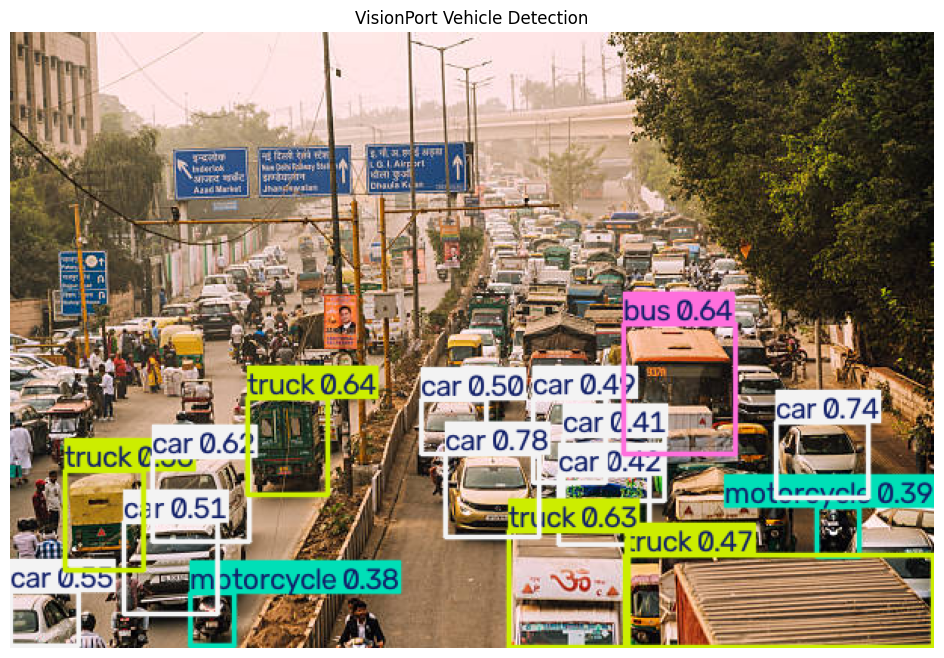

In [ ]:
import cv2
import matplotlib.pyplot as plt
from collections import Counter

# Read uploaded image
image = cv2.imread(image_path)

# Vehicle categories
vehicle_classes = [
    "bicycle",
    "car",
    "motorcycle",
    "bus",
    "truck"
]

# Get vehicle class IDs
vehicle_ids = [
    i for i, name in model.names.items()
    if name in vehicle_classes
]

# Perform detection
results = model(
    image,
    conf=0.35,
    classes=vehicle_ids,
    verbose=False
)

# Draw bounding boxes
output = results[0].plot()

# Count detected vehicles
counts = Counter()

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    confidence = float(box.conf[0])

    counts[name] += 1

    print(f"{name.upper()} - {confidence*100:.2f}% confidence")

# Display summary
print("\n----- VEHICLE SUMMARY -----")

for name, count in counts.items():
    print(f"{name.upper()}: {count}")

print("TOTAL VEHICLES:", sum(counts.values()))

# Display output image
output = cv2.cvtColor(output, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(output)
plt.axis("off")
plt.title("VisionPort Vehicle Detection")
plt.show()